## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


In [61]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan     
import itertools
from scipy.stats import qmc
import math

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Note to selves: both 2:2 and 3:1 still need that we remove omega pts if they are already crit pts

Also note to self: needed to say CritPts[a].coords instead of CritPts[a] here for checking 4 distinct to actually work. Should we update elsewhere? check.

## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

In [11]:
CritPts = ex.example_2_13()
CritPts

[(parent module of (0.0, 0.0) is 0),
 (parent module of (7.0, 0.0) is 0),
 (parent module of (0.0, 4.0) is 0),
 (parent module of (7.0, 4.0) is 0),
 (parent module of (0.0, 8.0) is 0),
 (parent module of (0.0, 11.0) is 0),
 (parent module of (0.0, 0.0) is 1),
 (parent module of (7.0, 0.0) is 1),
 (parent module of (0.0, 4.0) is 1),
 (parent module of (7.0, 4.0) is 1),
 (parent module of (0.0, 8.0) is 1),
 (parent module of (0.0, 11.0) is 1)]

**********
Computed 1848 points (with duplicates)
Without duplicates 60


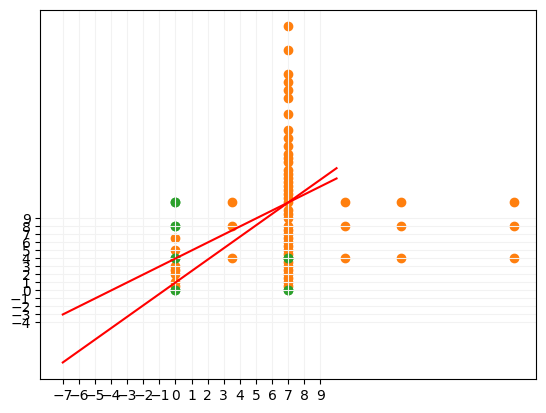

In [14]:
CritPts = ex.example_2_13()
name = "2_13"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [22]:
CritPts = ex.example_2_13()
CritPts
Omega_pts = []
length = len(CritPts)

for a in range(length):
    for b in range(a + 1, length):
        for c in range(b + 1, length):
            for d in range(c, length):
                if omega.check_4distinct([CritPts[a].coords, CritPts[b].coords, CritPts[c].coords, CritPts[d].coords]):
                    list1, list2 = omega.algo_2v2_paired([CritPts[a], CritPts[b], CritPts[c], CritPts[d]])
                    Omega_pts+=list2 

beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 11)]
beepbeep [(0, 0), (7, 0), (7, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (

In [27]:
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2.13_2v2_paired')

beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 8)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 11)]
beepbeep [(0, 0), (7, 0), (7, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (

### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

**********
Computed 1852 points (with duplicates)
Without duplicates 55


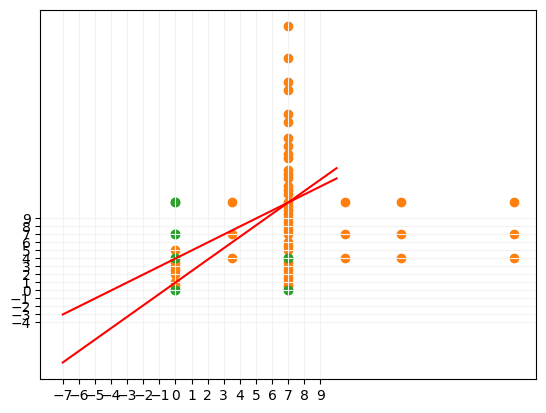

In [3]:
CritPts = ex.example_2_11()
name = "2_11"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [4]:
CritPts = ex.example_2_11()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2.11_2v2_paired')

beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (7, 4), (0, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 0)]
beepbeep [(0, 0), (7, 0), (7, 4), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 7), (0, 7)]
beepbeep [(0, 0), (7, 0), (0, 7), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 7), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 7), (0, 7)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 11), (0, 11)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (7, 4)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 7)]
beepbeep [(0, 0), (7, 0), (0, 0), (0, 11)]
beepbeep [(0, 0), (7, 0), (7, 0), (7, 0)]
beepbeep [(0, 0), (7, 0), (

### Example 1
$M=[0,7]\times[0,8]$ and $N=[1,8]\times[1,9]$

In [ ]:
CritPts = ex.example_1()
name = "1"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

In [29]:
CritPts = ex.example_1()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_1_2v2_paired')

beepbeep [(0, 0), (7, 0), (0, 8), (0, 8)]
beepbeep [(0, 0), (7, 0), (1, 1), (1, 1)]
beepbeep [(0, 0), (7, 0), (8, 1), (8, 1)]
beepbeep [(0, 0), (7, 0), (1, 9), (1, 9)]
beepbeep [(0, 0), (0, 8), (1, 1), (1, 1)]
beepbeep [(0, 0), (0, 8), (8, 1), (8, 1)]
beepbeep [(0, 0), (0, 8), (1, 9), (1, 9)]
beepbeep [(0, 0), (1, 1), (8, 1), (8, 1)]
beepbeep [(0, 0), (1, 1), (1, 9), (1, 9)]
beepbeep [(0, 0), (8, 1), (1, 9), (1, 9)]
beepbeep [(7, 0), (0, 8), (1, 1), (1, 1)]
beepbeep [(7, 0), (0, 8), (8, 1), (8, 1)]
beepbeep [(7, 0), (0, 8), (1, 9), (1, 9)]
beepbeep [(7, 0), (1, 1), (8, 1), (8, 1)]
beepbeep [(7, 0), (1, 1), (1, 9), (1, 9)]
beepbeep [(7, 0), (8, 1), (1, 9), (1, 9)]
beepbeep [(0, 8), (1, 1), (8, 1), (8, 1)]
beepbeep [(0, 8), (1, 1), (1, 9), (1, 9)]
beepbeep [(0, 8), (8, 1), (1, 9), (1, 9)]
beepbeep [(1, 1), (8, 1), (1, 9), (1, 9)]
**********
Computed 13 points (with duplicates)
Without duplicates 9


### Example 2 
$M=[0,4]\times[0,4]$ and $N=[1,3]\times[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

In [ ]:
CritPts = ex.example_2()
name = "2"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)


In [30]:
CritPts = ex.example_2()
Omega_pts = omega.output_alg_2_2_paired(CritPts, 'Example_2_2v2_paired')

beepbeep [(0, 0), (4, 0), (0, 4), (0, 4)]
beepbeep [(0, 0), (4, 0), (1, 0), (1, 0)]
beepbeep [(0, 0), (4, 0), (3, 0), (3, 0)]
beepbeep [(0, 0), (4, 0), (1, 4), (1, 4)]
beepbeep [(0, 0), (0, 4), (1, 0), (1, 0)]
beepbeep [(0, 0), (0, 4), (3, 0), (3, 0)]
beepbeep [(0, 0), (0, 4), (1, 4), (1, 4)]
beepbeep [(0, 0), (1, 0), (3, 0), (3, 0)]
beepbeep [(0, 0), (1, 0), (1, 4), (1, 4)]
beepbeep [(0, 0), (3, 0), (1, 4), (1, 4)]
beepbeep [(4, 0), (0, 4), (1, 0), (1, 0)]
beepbeep [(4, 0), (0, 4), (3, 0), (3, 0)]
beepbeep [(4, 0), (0, 4), (1, 4), (1, 4)]
beepbeep [(4, 0), (1, 0), (3, 0), (3, 0)]
beepbeep [(4, 0), (1, 0), (1, 4), (1, 4)]
beepbeep [(4, 0), (3, 0), (1, 4), (1, 4)]
beepbeep [(0, 4), (1, 0), (3, 0), (3, 0)]
beepbeep [(0, 4), (1, 0), (1, 4), (1, 4)]
beepbeep [(0, 4), (3, 0), (1, 4), (1, 4)]
beepbeep [(1, 0), (3, 0), (1, 4), (1, 4)]
**********
Computed 8 points (with duplicates)
Without duplicates 6


###### remark: in this example we should not need the omega pts on the boundary of the support 

## SoCG examples
- random rectangle modules
- random sets of points (not just rect mods) (maybe poiss pt pr in rectangle)
- project points of bunny to plane

- what is the dependence of num of switch points on num of pts in M and N? 
- unbalanced modules: M has more points than N
- How many duplcate omega points do we get in different cases? 

# Poisson points with blue noise

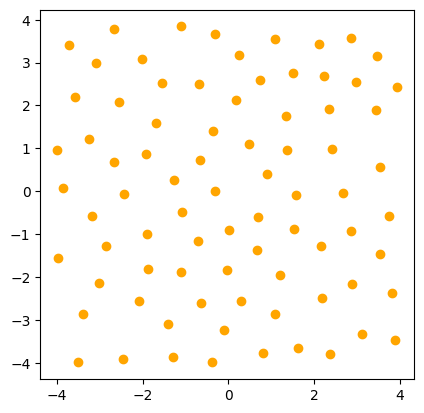

In [67]:
poisson_intensity = 30

radius = 1 / (2 * (math.sqrt(poisson_intensity)))
poissonpts = ex.make_poisson(inputt, poisson_intensity, radius, display=True)